# Cross-dataset comparison of the dataset statistics

Each `<ds>_stats` notebook describes one dataset from the point of view of
Tiny-YOLO and the embedded target (input 416, 13×13 and 26×26 grids, 256 slots of
`yolo_post`, INT8). This notebook puts them side by side: how many objects and how
dense, how small once resized, how many training targets are lost and why, how
balanced the classes are, how far the pixels are from the INT8 calibration images,
how well the anchors fit, and which dataset is hardest overall.

**Source.** The versioned outputs of the statistics notebooks ([voc](voc/voc_stats.ipynb), [coco](coco/coco_stats.ipynb), [kitti](kitti/kitti_stats.ipynb), [visdrone](visdrone/visdrone_stats.ipynb), [crowdhuman](crowdhuman/crowdhuman_stats.ipynb), [exdark](exdark/exdark_stats.ipynb), [flir](flir/flir_stats.ipynb), [auair](auair/auair_stats.ipynb), [dronevehicle](dronevehicle/dronevehicle_stats.ipynb), [hituav](hituav/hituav_stats.ipynb), [uavdt](uavdt/uavdt_stats.ipynb), [asl](asl/asl_stats.ipynb)), read by
`tools/notebooks/jeux.py`; the figures come from `tools/figures/jeux.py`. Nothing
is recomputed or typed by hand: a statistics notebook re-run and committed shows up
here after `Run All`. No data, no GPU.

**Caution.** Annotation counts cover whole splits; pixel statistics cover 200
images per split. A notebook run without its M11 cfg (`build/m11/cfg/`, absent on
a fresh Colab runtime) uses the Tiny-YOLOv3 COCO anchors and masks for the lost
targets and the "anchors in use": the provenance table below says which. A run that
stopped after its tables without error is used and marked `partial`.
Synthesis of each dataset: [stats-jeux.md](../docs/tasks/stats-jeux.md).

Generated by `python -m tools.notebooks`: edit
`tools/notebooks/gabarits.py:stats_analysis`, not this file.

## Parameters

In [1]:
DATASETS = None  # datasets analysed (e.g. ['voc', 'kitti']); None: every executed _stats notebook
OUT      = 'build/notebooks/jeux'  # PNG files (relative to the repository root)

## Environment

In [2]:
import os
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

CANDIDATES = (Path.cwd(), *Path.cwd().parents, Path("/content/EmbeddedComputervision"))
ROOT = next((d for d in CANDIDATES if (d / "tools" / "notebooks").is_dir()), None)
if ROOT is None:
    raise SystemExit(f"repository not found from {Path.cwd()}")
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "python")]

from tools.figures import jeux as FJ
from tools.notebooks import jeux as J

data, pending = J.load_all(datasets=DATASETS)
if not data:
    raise SystemExit("no executed notebook in notebooks/*/*_stats.ipynb")
OBS = J.observations(data)


def show(paths):
    for p in paths:
        display(Image(data=Path(p).read_bytes(), format="png"))


print(f"repository: {ROOT}")
print(f"{len(data)} datasets loaded: {', '.join(d['label'] for d in data.values())}")
for ds, why in pending.items():
    print(f"  not analysed: {ds} — {why}")
display(Markdown(J.provenance_table(data)))

repository: /home/leonard/Documents/Perso/EmbeddedComputervision
10 datasets loaded: VOC, KITTI, CrowdHuman, ExDark, FLIR, VisDrone, AU-AIR, DroneVehicle, HIT-UAV, UAVDT
  not analysed: coco — notebooks/coco/coco_stats.ipynb (CalledProcessError: Command 'python tools/data_stats.py --dataset coco --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --g)
  not analysed: asl — notebooks/asl/asl_stats.ipynb (not executed)


| dataset | notebook | revision | run | anchors (cfg) | fallback to COCO cfg | splits |
|---|---|---|---|---|---|---|
| VOC | [voc_stats.ipynb](voc/voc_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-voc | no | 2007:trainval, 2012:trainval, 2007:test |
| KITTI | [kitti_stats.ipynb](kitti/kitti_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, val |
| CrowdHuman | [crowdhuman_stats.ipynb](crowdhuman/crowdhuman_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, val |
| ExDark | [exdark_stats.ipynb](exdark/exdark_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, test |
| FLIR | [flir_stats.ipynb](flir/flir_stats.ipynb) | 7738bf9 | partial | tiny-yolov3-coco | yes | train, val |
| VisDrone | [visdrone_stats.ipynb](visdrone/visdrone_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, val |
| AU-AIR | [auair_stats.ipynb](auair/auair_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, val |
| DroneVehicle | [dronevehicle_stats.ipynb](dronevehicle/dronevehicle_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, test |
| HIT-UAV | [hituav_stats.ipynb](hituav/hituav_stats.ipynb) | 7738bf9 | partial | tiny-yolov3-coco | yes | train, test |
| UAVDT | [uavdt_stats.ipynb](uavdt/uavdt_stats.ipynb) | 7738bf9 | complete | tiny-yolov3-coco | yes | train, test |

## Overview

One row per dataset (whole dataset, all splits). Sizes are seen by the network
(letterbox 416); "< fine cell" is the share of objects under the 16 px stride of the
26×26 head; "of which collisions" is the part of the lost targets due to two objects
on the same cell and anchor (the rest is anchors, section 4).

In [3]:
display(Markdown(J.summary_table(data)))

| dataset | view | classes | images | objects | objects/img (med / max) | median side (px) | small < 32² (%) | < fine cell (%) | lost targets (%) | of which collisions (%) | channels | luminance | IoU cfg anchors | IoU k-means |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| VOC | ground | 20 | 21,503 | 62,199 | 2 / 56 | 116 | 8.4 | 0.3 | 0.7 | 0.69 | 3 | 112 | 0.603 | 0.631 |
| KITTI | ground | 8 | 7,481 | 40,570 | 5 / 22 | 20 | 70.9 | 25.5 | 42.4 | 2.55 | 3 | 98 | 0.524 | 0.649 |
| CrowdHuman | ground | 1 | 19,370 | 566,493 | 20 / 468 | 34 | 47.5 | 10.0 | 32.8 | 7.44 | 3 | 114 | 0.529 | 0.680 |
| ExDark | ground | 12 | 5,563 | 17,498 | 2 / 33 | 69 | 18.1 | 1.0 | 4.0 | 0.46 | 3 | 33 | 0.609 | 0.615 |
| FLIR | ground | 15 | 11,886 | 191,728 | 15 / 93 | 11 | 85.6 | 50.7 | 68.2 | 1.20 | 1 | 133 | 0.456 | 0.564 |
| VisDrone | aerial | 10 | 7,019 | 381,963 | 43 / 902 | 7 | 97.0 | 75.3 | 85.9 | 0.52 | 3 | 97 | 0.350 | 0.603 |
| AU-AIR | aerial | 8 | 32,823 | 131,977 | 3 / 56 | 18 | 79.8 | 34.7 | 47.1 | 0.17 | 3 | 123 | 0.492 | 0.668 |
| DroneVehicle | aerial | 2 | 14,726 | 235,858 | 12 / 206 | 28 | 65.4 | 0.4 | 4.8 | 1.20 | 3 | 80 | 0.556 | 0.734 |
| HIT-UAV | aerial | 4 | 2,579 | 22,298 | 6 / 42 | 14 | 84.2 | 44.6 | 62.5 | 1.28 | 1 | 125 | 0.597 | 0.701 |
| UAVDT | aerial | 3 | 40,735 | 798,795 | 15 / 107 | 12 | 96.9 | 56.9 | 80.5 | 0.19 | 3 | 97 | 0.533 | 0.712 |

## 1. Scale and density

Images and objects per dataset (log scale), then objects per image: median (●) and maximum (○). The dashed line is the 256 slots of the hardware post-processing (`yolo_post`, M9.1): an image to its right loses detections on the board. Green: ground views; indigo: drone views (same colours in every figure).

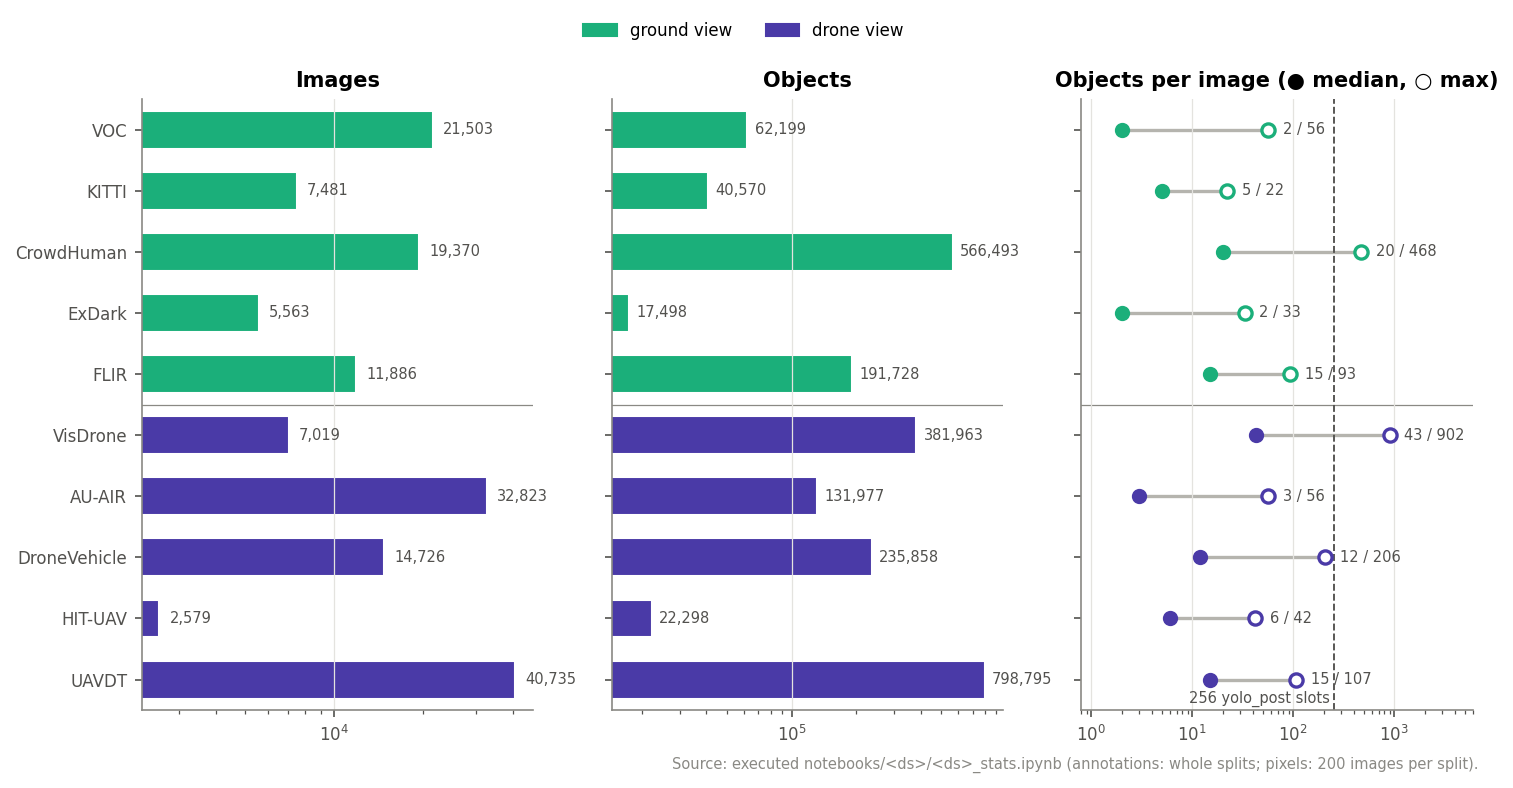

**Finding.** Most objects: UAVDT (798,795), CrowdHuman (566,493), VisDrone (381,963); fewest: ExDark (17,498), HIT-UAV (22,298), KITTI (40,570). Densest images (median objects per image): VisDrone (43), CrowdHuman (20), FLIR (15).

In [4]:
show(FJ.PLOTS['taille'](data, OUT))
display(Markdown("**Finding.** " + OBS['taille']))

## 2. Object size seen by the network

COCO size categories (small < 32², medium < 96², large) at the original resolution (pale bar) and after letterbox to 416 (dark bar). The shift between the two bars is what the resize costs: a dataset with wide or large images (KITTI, VisDrone, UAVDT, AU-AIR) turns most of its objects into small ones.

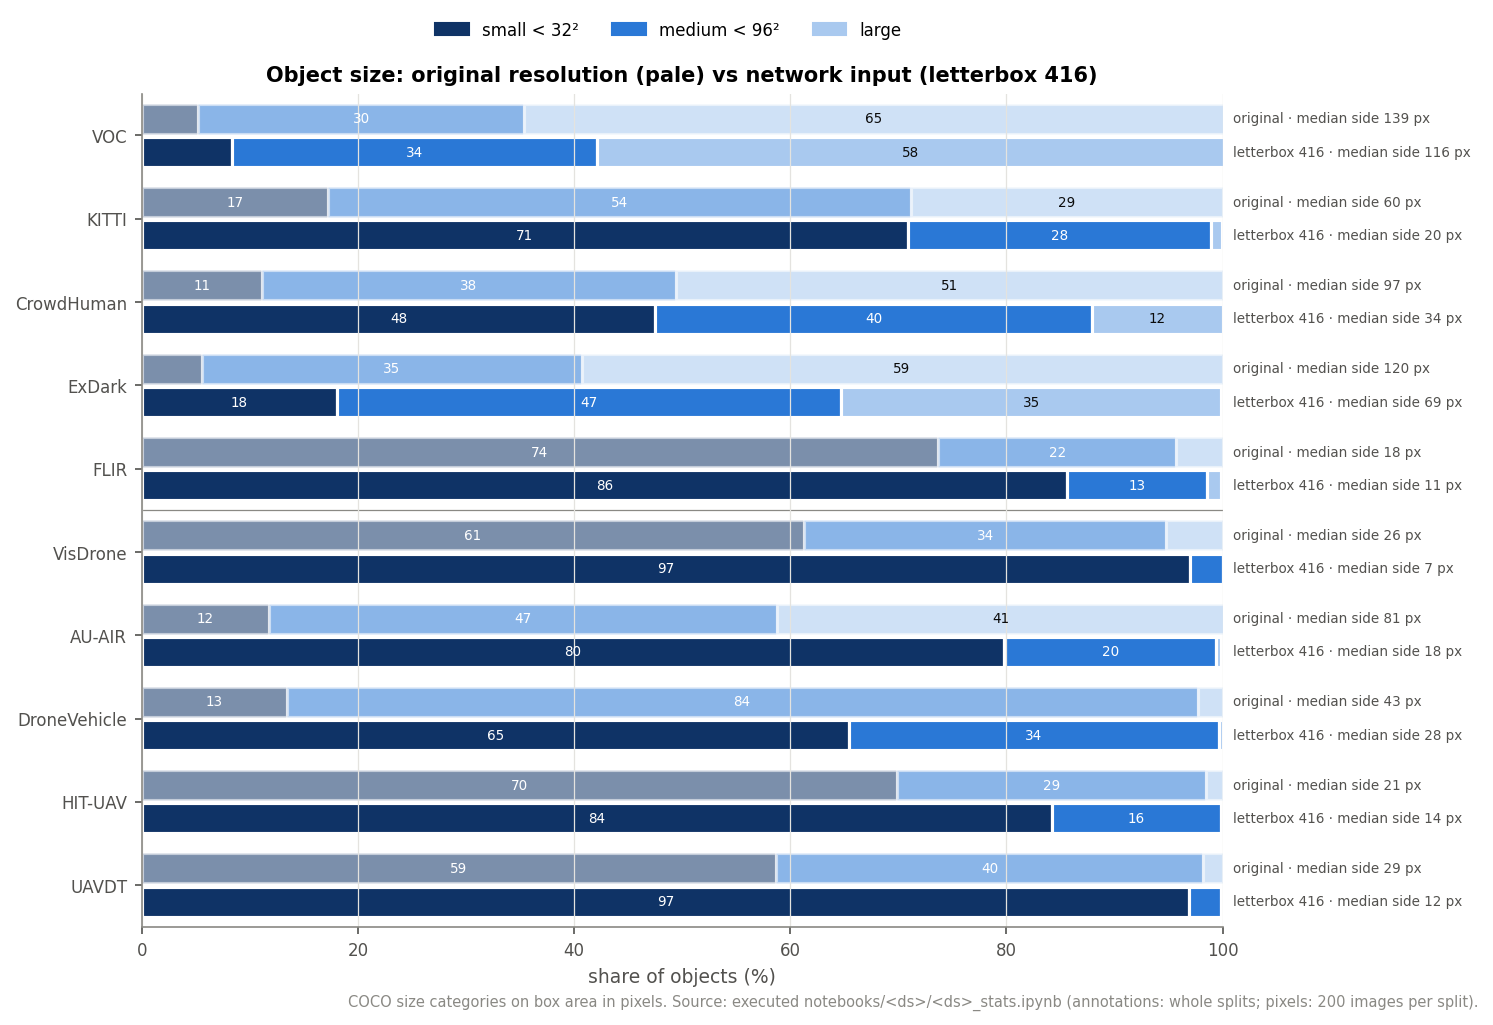

**Finding.** After letterbox to 416, the share of small objects (< 32²) is highest for VisDrone (97.0 %), UAVDT (96.9 %), FLIR (85.6 %) and lowest for VOC (8.4 %), ExDark (18.1 %), CrowdHuman (47.5 %). Median side seen by the network: from VisDrone (7 px) to VOC (116 px).

In [5]:
show(FJ.PLOTS['objets'](data, OUT))
display(Markdown("**Finding.** " + OBS['objets']))

## 3. Objects smaller than a grid cell

Share of objects whose longest side is below the stride of each Tiny-YOLOv3 head (32 px for 13×13, 16 px for 26×26), with letterbox (●, aspect kept) and stretch (○, aspect lost); right, objects less than 8 px high. A long bar between ○ and ● says that stretching the image would recover many objects.

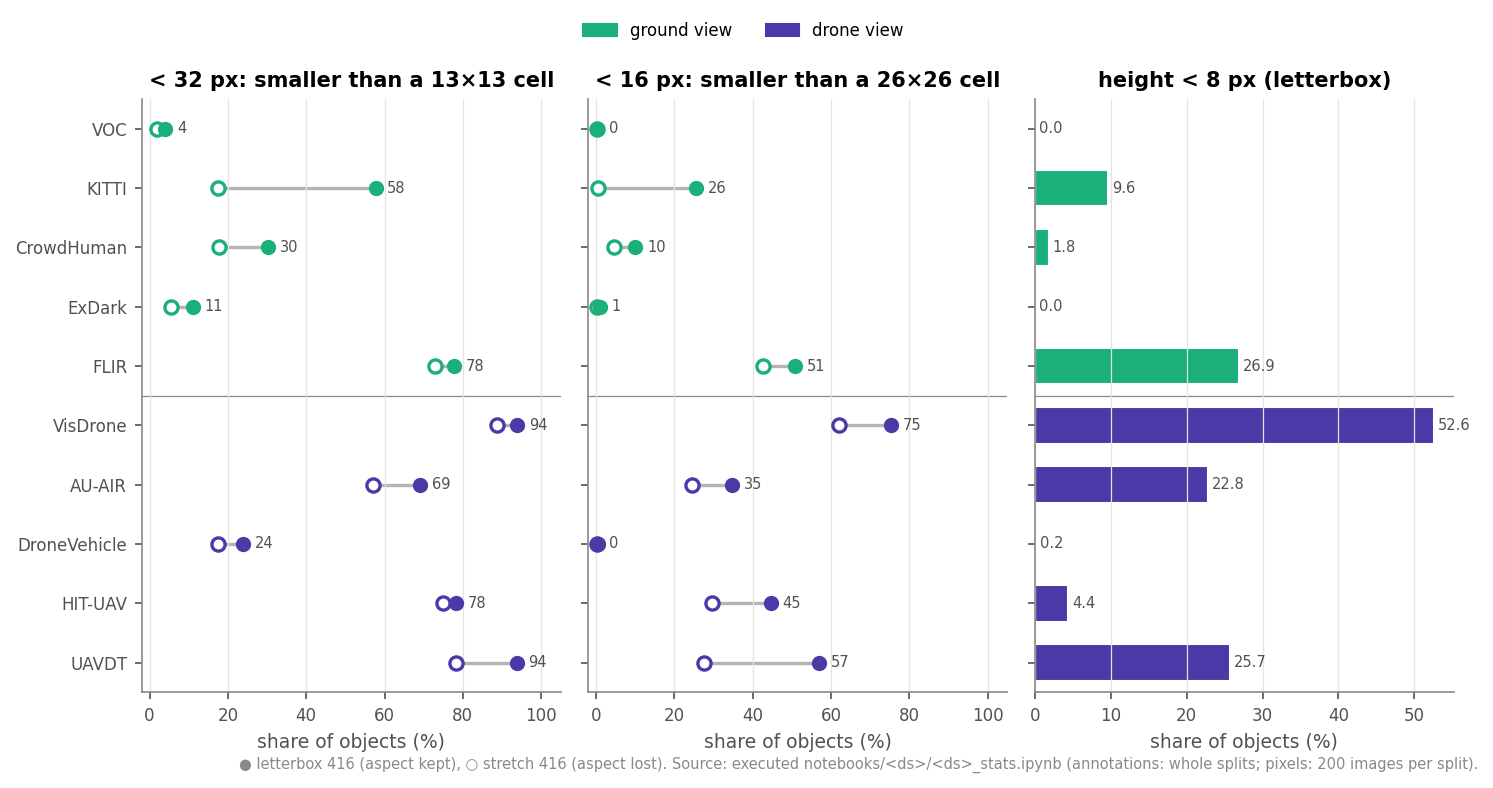

**Finding.** Objects smaller than a 16 px cell of the fine 26×26 head: VisDrone (75.3 %), UAVDT (56.9 %), FLIR (50.7 %). Objects under 8 px high: VisDrone (52.6 %), FLIR (26.9 %), UAVDT (25.7 %). Stretch instead of letterbox helps most where images are far from square: UAVDT (29.3 points), KITTI (25.1 points).

In [6]:
show(FJ.PLOTS['cellules'](data, OUT))
display(Markdown("**Finding.** " + OBS['cellules']))

## 4. Lost training targets: anchors or crowding?

Share of non-difficult objects that `build_targets` drops, split by cause. Grey: the best anchor of the box belongs to no head (with the Tiny-YOLOv3 COCO masks 3,4,5 / 1,2,3, anchor 0 = 10×14 px is unused, so the smallest boxes are never trained). Colour: two objects on the same cell and anchor (only one is kept). The grey part is fixed by dataset anchors and masks (M11 cfg); the coloured part needs a finer grid.

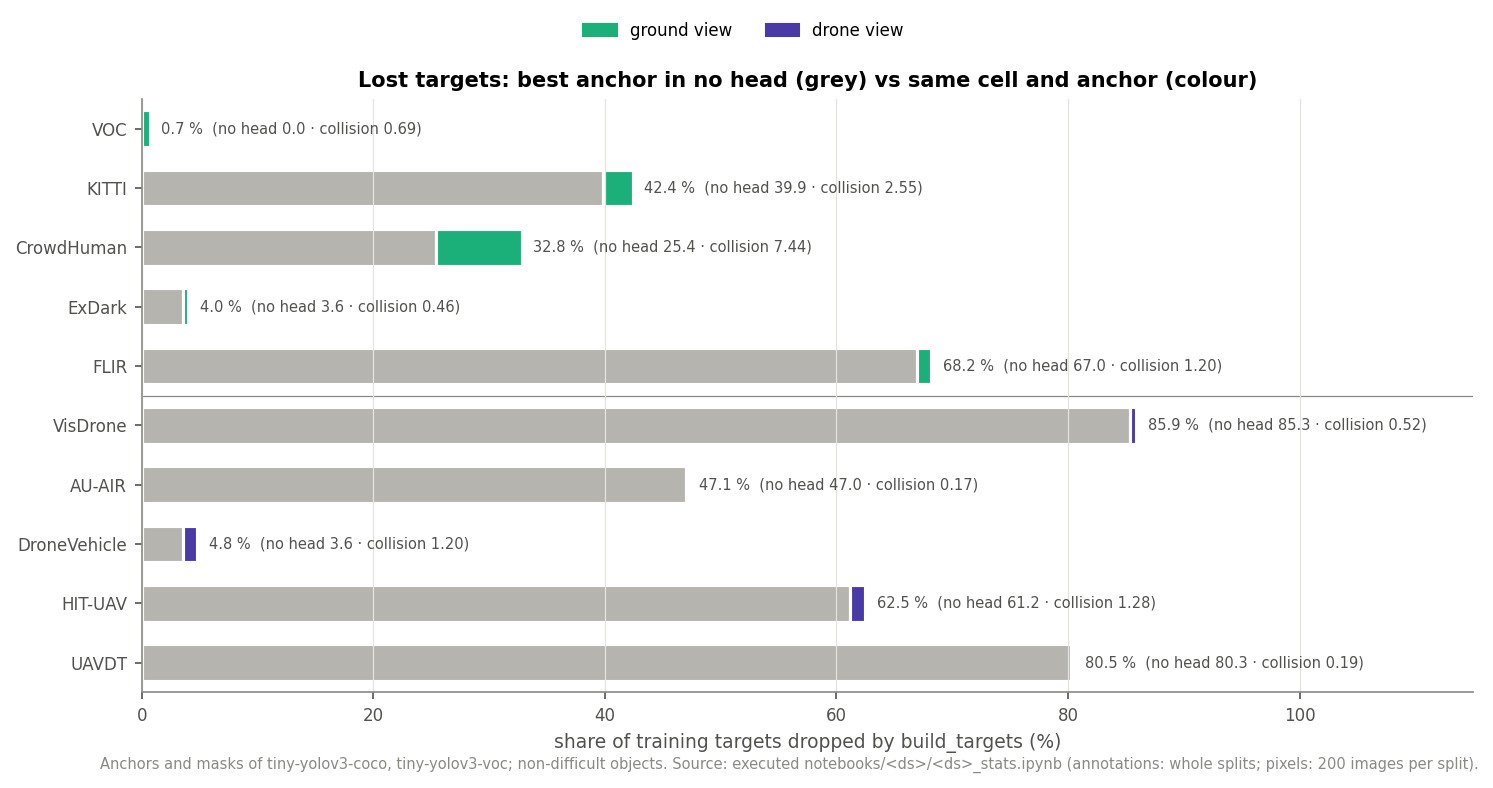

**Finding.** Most lost targets come from anchors, not crowding: orphans (best anchor in no head, e.g. anchor 0 = 10×14 px with the COCO masks 3,4,5 / 1,2,3) reach VisDrone (85.3 %), UAVDT (80.3 %), FLIR (67.0 %), while real cell + anchor collisions stay at CrowdHuman (7.44 %), KITTI (2.55 %), HIT-UAV (1.28 %). Images above the 256 `yolo_post` slots: CrowdHuman, VisDrone.

In [7]:
show(FJ.PLOTS['densite'](data, OUT))
display(Markdown("**Finding.** " + OBS['densite']))

## 5. Class balance

Share of each class, sorted, one panel per dataset (log scale). Below each panel: the most frequent class, the most / least frequent ratio and the normalised entropy (1 = all classes equally frequent). A steep staircase means rare classes the fine-tuning will barely see.

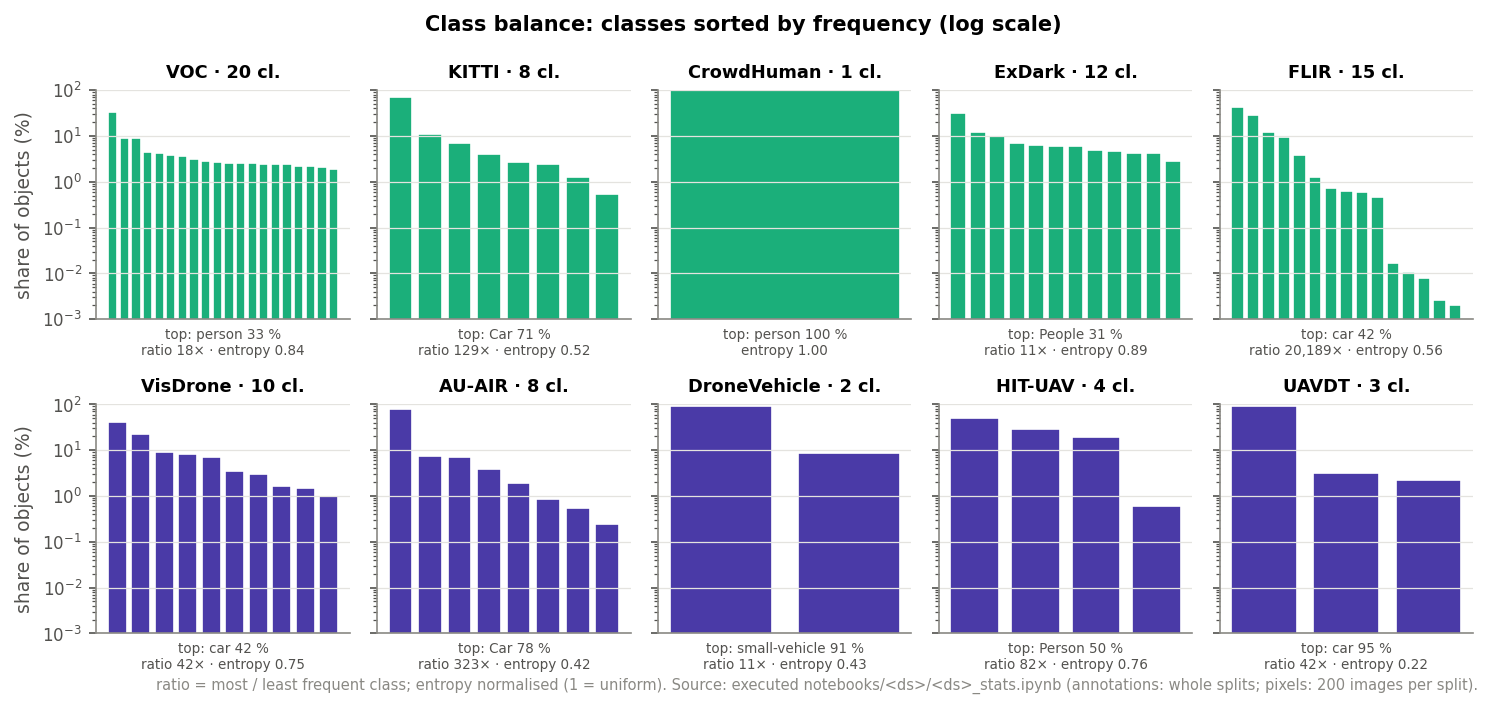

**Finding.** Largest most / least frequent class ratios: FLIR (20,189×), AU-AIR (323×), KITTI (129×). Least balanced (normalised entropy, 1 = uniform): UAVDT (0.22), AU-AIR (0.42), DroneVehicle (0.43).

In [8]:
show(FJ.PLOTS['classes'](data, OUT))
display(Markdown("**Finding.** " + OBS['classes']))

## 6. Pixels against the INT8 calibration images

Mean luminance (bar) and per-channel means (R, G, B ticks), then contrast (mean channel standard deviation), against VOC (dashed), whose images calibrated the INT8 scales (M4). Right: the letterbox factor 416 / longest side of the main resolution; small factors shrink objects the most.

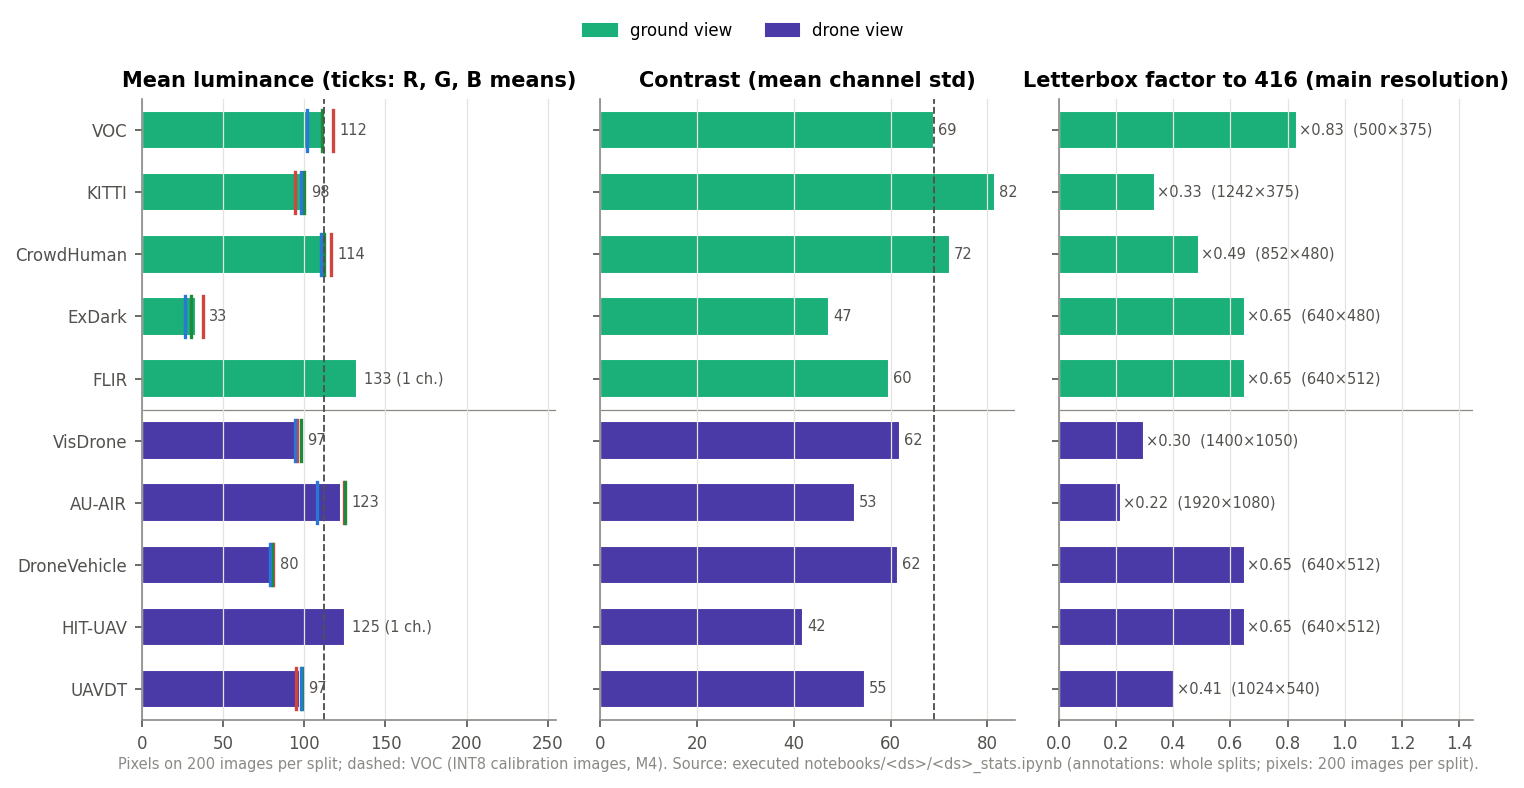

**Finding.** Darkest datasets: ExDark (33), DroneVehicle (80), VisDrone (97), against 112 for VOC (INT8 calibration images). Single-channel (thermal) images: FLIR, HIT-UAV; they are replicated to 3 channels at the input.

In [9]:
show(FJ.PLOTS['images'](data, OUT))
display(Markdown("**Finding.** " + OBS['images']))

## 7. Anchors

Left: mean IoU between the training boxes and their best anchor, for the anchors in use (○), k-means anchors computed on the dataset (●) and the Tiny-YOLOv2 VOC anchors (×). The gain written on the right is what re-clustering the anchors brings. Right: the k-means anchors (k = 6) of every dataset against the COCO anchors (□); anchor 0 (×) is the one no COCO head uses.

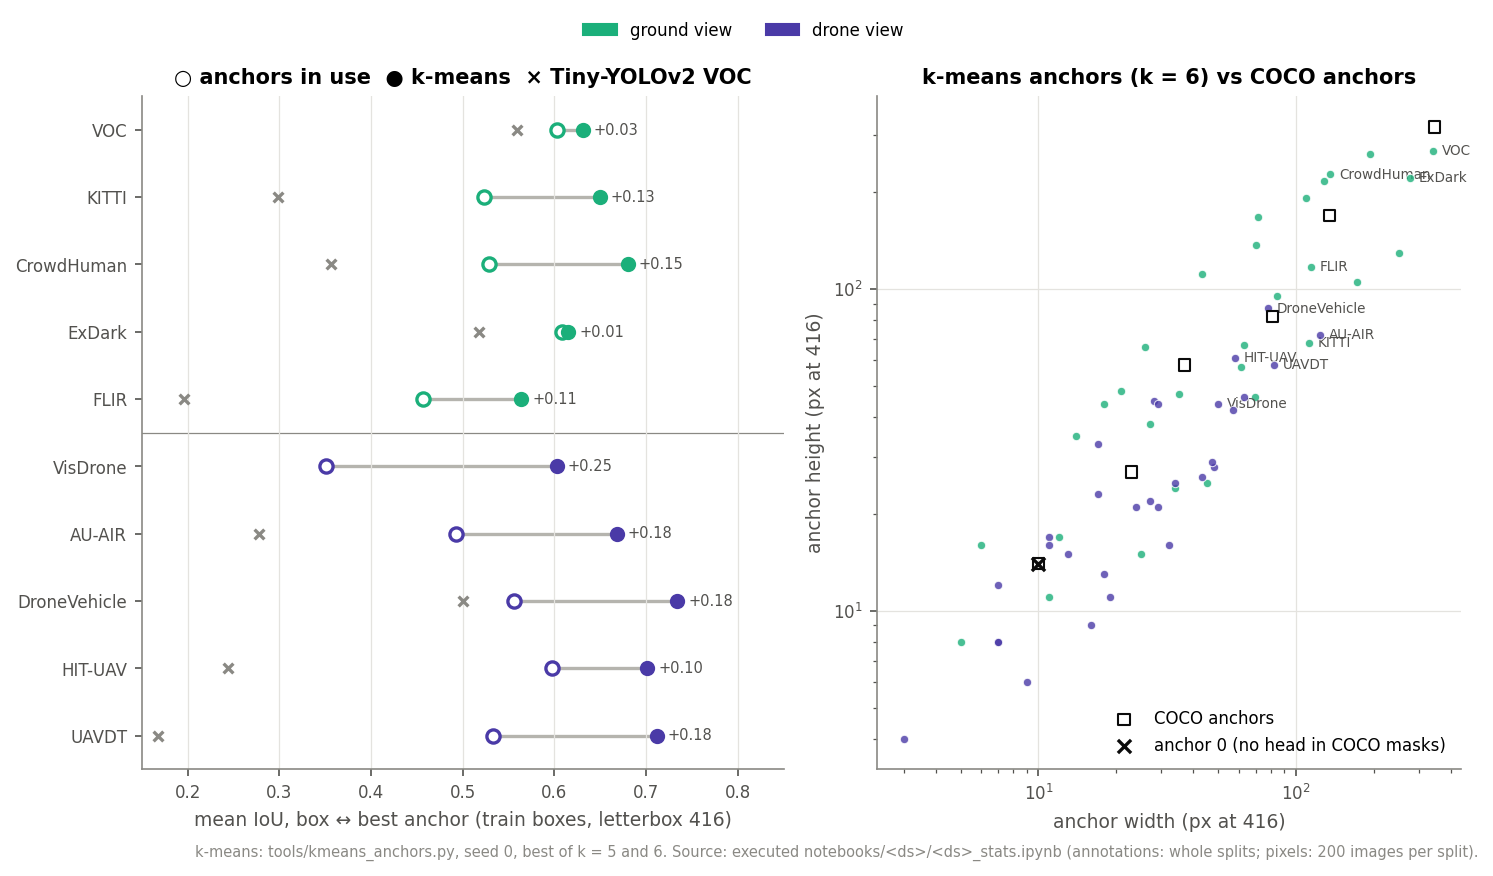

**Finding.** Lowest mean IoU with the anchors in use: VisDrone (0.350), FLIR (0.456), AU-AIR (0.492). Re-clustering (k-means) gains most for VisDrone (0.252), UAVDT (0.178), DroneVehicle (0.178) IoU.

In [10]:
show(FJ.PLOTS['ancres'](data, OUT))
display(Markdown("**Finding.** " + OBS['ancres']))

## 8. Train ↔ test gap

Total variation distance between the train and test distributions of each quantity (0: same histogram, 1: disjoint). Above about 0.1, scores on the test split say less about the training split, and the reverse.

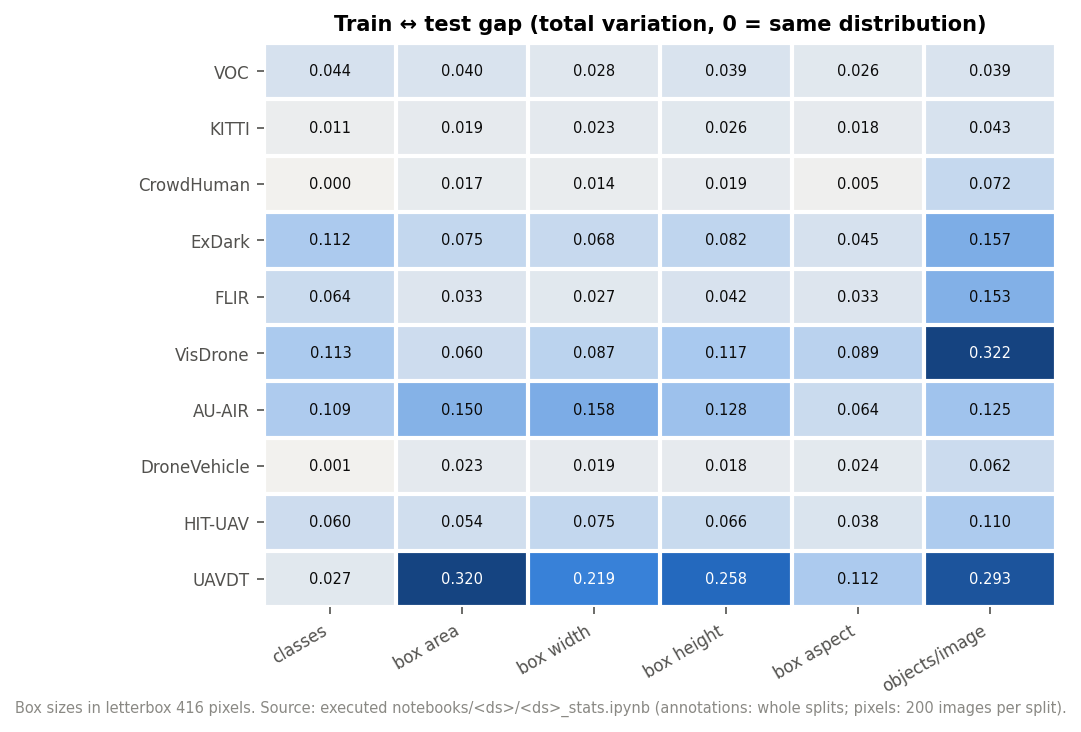

**Finding.** Largest train ↔ test gaps (total variation): VisDrone on per_image (0.322), UAVDT on area_in (0.320), AU-AIR on w_in (0.158); values under 0.05 mean the test split looks like the training split.

In [11]:
show(FJ.PLOTS['ecart'](data, OUT))
display(Markdown("**Finding.** " + OBS['ecart']))

## 9. What the published weights can name

Share of objects whose class has an equivalent among the VOC (20) or COCO (80) classes (`MAPPINGS`): only these objects are scored in the out-of-domain notebooks (T14.5) of `tiny-yolov2-voc` and `tiny-yolov3-coco`.

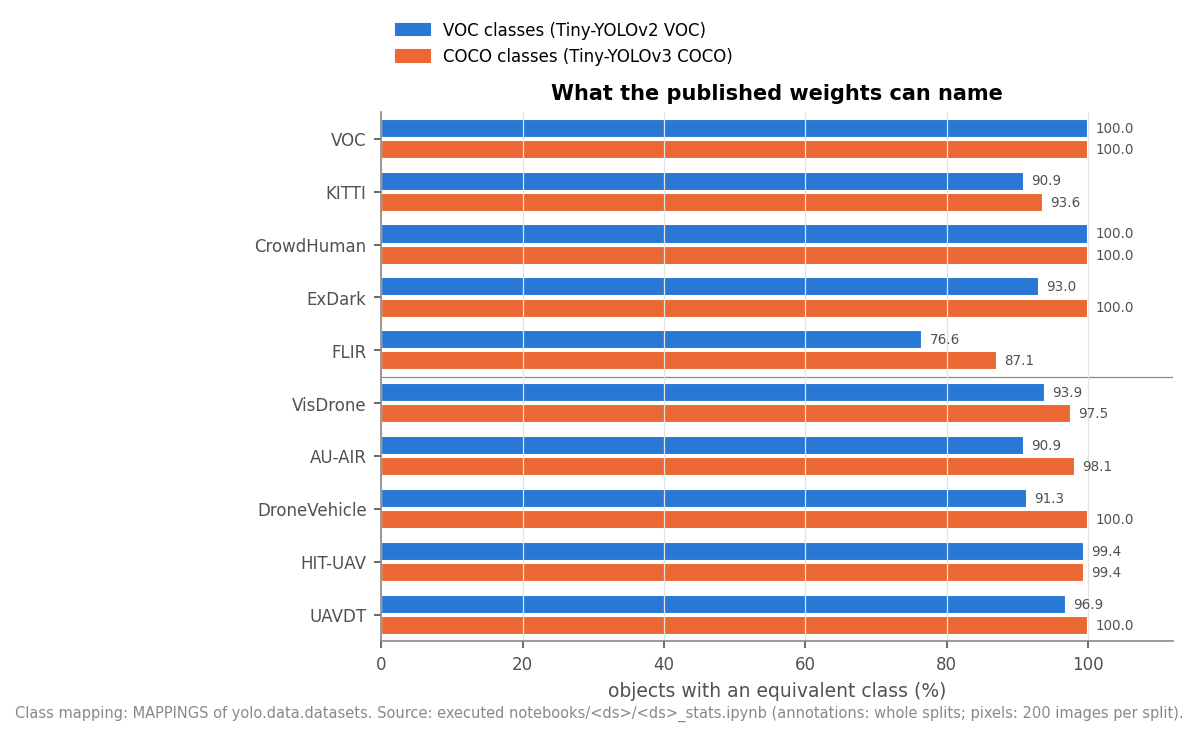

**Finding.** Lowest share of objects the published weights can name: VOC classes FLIR (76.6 %), AU-AIR (90.9 %), KITTI (90.9 %); COCO classes FLIR (87.1 %), KITTI (93.6 %), VisDrone (97.5 %).

In [12]:
show(FJ.PLOTS['couverture'](data, OUT))
display(Markdown("**Finding.** " + OBS['couverture']))

## 10. Annotation quality

Boxes clipped to the image, removed by the loader, under 2 px at the input, duplicates (IoU > 0.95) and ignore regions (DontCare…) removed by the loader. Colour: share of the column maximum, to spot the outlier of each column.

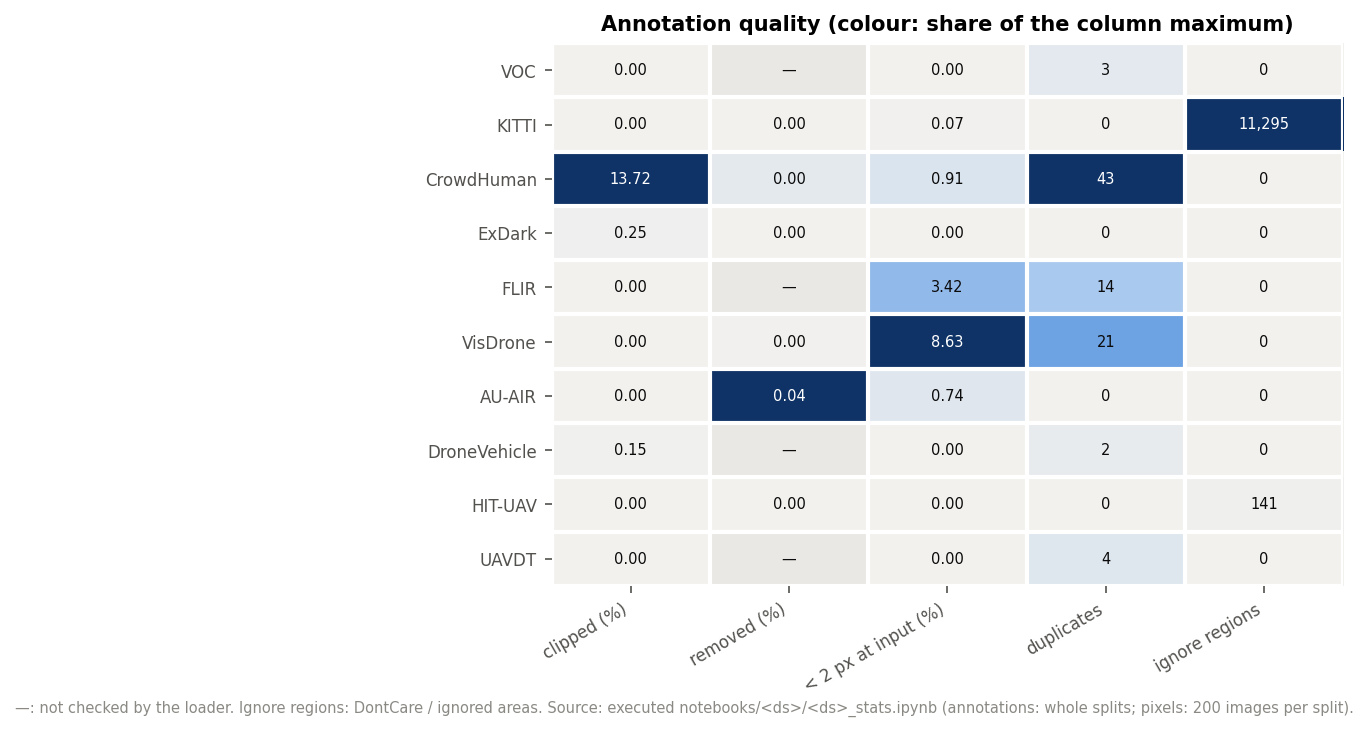

**Finding.** Clipped boxes: CrowdHuman (13.72 %), ExDark (0.25 %), DroneVehicle (0.15 %); removed by the loader: AU-AIR (0.04 %), CrowdHuman (< 0.01 %), VisDrone (< 0.01 %); boxes under 2 px at the input: VisDrone (8.63 %), FLIR (3.42 %), CrowdHuman (0.91 %). The other datasets are cleaner.

In [13]:
show(FJ.PLOTS['qualite'](data, OUT))
display(Markdown("**Finding.** " + OBS['qualite']))

## 11. Overview: which dataset is hardest for the embedded Tiny-YOLO?

Seven indicators, each normalised from 0 (easiest dataset) to 1 (hardest), and their mean; datasets sorted by that mean. Raw values are written in the cells. The weights are equal by choice: the ranking is a reading aid, not a score to optimise.

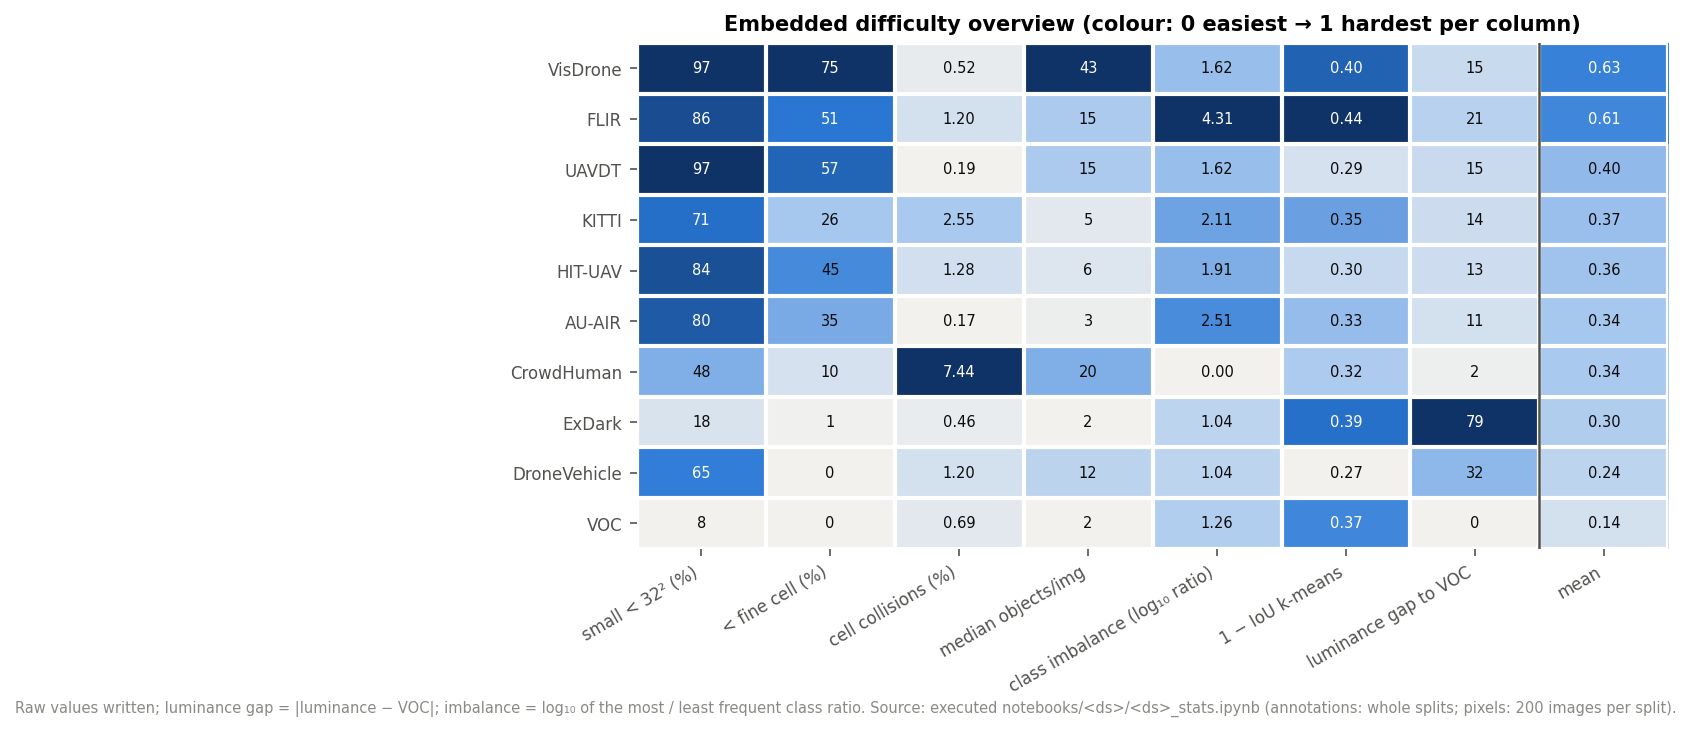

**Finding.** Ranking by mean normalised difficulty (hardest first): VisDrone (0.63), FLIR (0.61), UAVDT (0.40), KITTI (0.37), HIT-UAV (0.36), AU-AIR (0.34), CrowdHuman (0.34), ExDark (0.30), DroneVehicle (0.24), VOC (0.14).

In [14]:
show(FJ.PLOTS['difficulte'](data, OUT))
display(Markdown("**Finding.** " + OBS['difficulte']))

## Conclusions

Computed on the loaded datasets; they update with them.

In [15]:
display(Markdown(J.conclusions(data, pending)))
print("equivalent command:")
print(f"  python -m tools.notebooks.jeux --json {OUT}/jeux.json --figures {OUT}")

- **Drone views are a different regime**: on average 85 % small objects after letterbox 416, against 46 % for ground views (VOC 8 %). Few of their objects reach the 13×13 head; the 26×26 head (or a finer one, or a larger input) carries the detection.
- **Anchors before capacity**: with the COCO anchors and masks, KITTI 40 %, CrowdHuman 25 %, FLIR 67 %, VisDrone 85 %, AU-AIR 47 %, HIT-UAV 61 %, UAVDT 80 % of the objects have their best anchor in no head and are never trained. Dataset-specific anchors (k-means, M11 cfg) fix this before any change of architecture; real collisions stay small.
- **INT8 calibration**: ExDark (luminance 33) is far from the VOC calibration images; calibrate the quantisation scales on the dataset itself.
- **`yolo_post` slots**: CrowdHuman, VisDrone have images with more than 256 objects: the hardware post-processing would drop detections there.
- **Hardest to easiest** (mean normalised difficulty): VisDrone > FLIR > UAVDT > KITTI > HIT-UAV > AU-AIR > CrowdHuman > ExDark > DroneVehicle > VOC.
- **Caveat**: KITTI, CrowdHuman, ExDark, FLIR, VisDrone, AU-AIR, DroneVehicle, HIT-UAV, UAVDT were run without their M11 cfg; lost targets and "cfg" anchors use Tiny-YOLOv3 COCO. Re-run after `tools/m11.sh <ds>-prep` to see the fine-tuning cfg.
- **Not analysed**: coco: notebooks/coco/coco_stats.ipynb (CalledProcessError: Command 'python tools/data_stats.py --dataset coco --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --g); asl: notebooks/asl/asl_stats.ipynb (not executed)

equivalent command:
  python -m tools.notebooks.jeux --json build/notebooks/jeux/jeux.json --figures build/notebooks/jeux
